# R3 – Classical models: regression
**F20DL Group 5** · Requirement R3 (Abhinav, Raees)

Predict the exact Spotify `popularity` score (0–100) with classical models and compare them with a baseline.

| Step | What happens |
|---|---|
| Baseline | Always predict the training-set mean popularity |
| Models | Ridge regression (linear + L2), Decision Tree, k-NN, Random Forest |
| Tuning | Grid search with **10-fold StratifiedGroupKFold** on the training set (grouped by `song_id`, stratified by `pop_class`), scoring RMSE |
| Selection | Tuned models are re-fitted on the full training set and compared on the **validation** set |
| Feature groups | Each tuned model is re-trained on all / audio / metadata / no-artist features |
| Test set | **Not used here.** It is scored once at the end of the project (after R4) with `final_test()` |

Shared code (folds, pipelines, metrics) is in `r3_common.py`. Scalers sit inside a `Pipeline`, so they are fitted on the training part of each fold only.

In [1]:
import json, os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
import r3_common as rc

warnings.filterwarnings("ignore")
os.makedirs("results", exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format)

df, train, val, test = rc.load_data()
groups = rc.feature_groups(df)
FEATS, TARGET = groups["all"], "popularity"
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,} (test not used)")
for g, cols in groups.items():
    print(f"{g:10s} {len(cols):2d} columns")

Matplotlib is building the font cache; this may take a moment.


train 71,065 | val 15,237 | test 15,270 (test not used)
all        49 columns
audio      26 columns
metadata   23 columns
no_artist  34 columns


## 1. Baseline
A model that ignores the features and always predicts the training mean. Every real model has to beat this. Its R² on validation is ≈ 0 by construction.

In [2]:
baseline = DummyRegressor(strategy="mean").fit(train[FEATS], train[TARGET])
base_pred = baseline.predict(val[FEATS])
base_row = {"model": "Baseline (train mean)", **rc.regression_metrics(val[TARGET], base_pred),
            **rc.high_popularity_error(val[TARGET], base_pred)}
pd.DataFrame([base_row]).set_index("model")

,MSE,RMSE,MAE,R2,MAE_high,MAE_rest,n_high
model,,,,,,,
Baseline (train mean),280.263,16.741,13.503,-0.000,27.464,11.826,1634


## 2. Tuning
Hyperparameter grids and why:

- **Ridge** – `alpha` is the L2 penalty strength. Larger alpha shrinks coefficients more.
- **Decision Tree** – `max_depth` and `min_samples_leaf` control how far the tree can grow (overfitting vs underfitting).
- **k-NN** – `n_neighbors` (k) and whether closer neighbours count more (`weights`). Needs scaled inputs, which the pipeline does.
- **Random Forest** – `max_features` (features tried at each split) and `min_samples_leaf`. 100 trees.

k-NN and Random Forest are slow on 71k rows × 10 folds, so they are **tuned on a stratified 20,000-row subsample** of the training set (CV still grouped by song) and the chosen settings are then **re-fitted on the full training set**. Ridge and Decision Tree are tuned on the full training set.

In [3]:
SCORING = "neg_root_mean_squared_error"
specs = {
    "Ridge": (rc.make_pipeline(Ridge(), scale=True),
              {"alpha": [0.01, 0.1, 1, 10, 100, 1000]}, None),
    "Decision Tree": (rc.make_pipeline(DecisionTreeRegressor(random_state=rc.SEED), scale=False),
                      {"max_depth": [5, 10, 15, 20, None], "min_samples_leaf": [1, 10, 50]}, None),
    "k-NN": (rc.make_pipeline(KNeighborsRegressor(), scale=True),
             {"n_neighbors": [5, 15, 30, 50], "weights": ["uniform", "distance"]}, 20000),
    "Random Forest": (rc.make_pipeline(RandomForestRegressor(n_estimators=100, random_state=rc.SEED, n_jobs=1), scale=False),
                      {"max_features": ["sqrt", 0.33], "min_samples_leaf": [1, 5]}, 20000),
}
searches, tuning_rows = {}, []
for name, (pipe, grid, sub) in specs.items():
    gs, summary = rc.tune(name, pipe, grid, train, FEATS, TARGET, SCORING, subsample=sub)
    summary["cv_RMSE"] = -summary.pop("cv_mean"); summary["cv_RMSE_std"] = summary.pop("cv_std")
    searches[name] = gs; tuning_rows.append(summary)
tuning_table = pd.DataFrame(tuning_rows).set_index("model")
tuning_table

Ridge: best {'alpha': 10} | CV -10.6150 ± 0.1029 | 71,065 rows | 12.4s
Decision Tree: best {'max_depth': 10, 'min_samples_leaf': 10} | CV -10.2106 ± 0.1056 | 71,065 rows | 30.0s
k-NN: best {'n_neighbors': 15, 'weights': 'distance'} | CV -12.5208 ± 0.1040 | 20,000 rows | 3.6s
Random Forest: best {'max_features': 0.33, 'min_samples_leaf': 1} | CV -9.7686 ± 0.0679 | 20,000 rows | 36.6s


,tuned_on_rows,best_params,tuning_seconds,cv_RMSE,cv_RMSE_std
model,,,,,
Ridge,71065,"{""alpha"": 10}",12.400,10.615,0.103
Decision Tree,71065,"{""max_depth"": 10, ""min_samples_leaf"": 10}",30.000,10.211,0.106
k-NN,20000,"{""n_neighbors"": 15, ""weights"": ""distance""}",3.600,12.521,0.104
Random Forest,20000,"{""max_features"": 0.33, ""min_samples_leaf"": 1}",36.600,9.769,0.068


## 3. Validation results (all features)
Each tuned model is re-fitted on the full training set and scored on the validation set. `train_RMSE` is shown to spot overfitting (a big gap between train and validation). `MAE_high` is the error on the rare tracks with popularity > 60.

In [4]:
models, val_preds, rows = {}, {}, [base_row]
for name, gs in searches.items():
    m = rc.refit_full(gs, train, FEATS, TARGET)
    p = m.predict(val[FEATS])
    models[name], val_preds[name] = m, p
    rows.append({"model": name, **rc.regression_metrics(val[TARGET], p),
                 **rc.high_popularity_error(val[TARGET], p),
                 "train_RMSE": rc.regression_metrics(train[TARGET], m.predict(train[FEATS]))["RMSE"]})
val_table = pd.DataFrame(rows).set_index("model")
val_table

,MSE,RMSE,MAE,R2,MAE_high,MAE_rest,n_high,train_RMSE
model,,,,,,,,
Baseline (train mean),280.263,16.741,13.503,-0.000,27.464,11.826,1634,NaN
Ridge,113.378,10.648,8.355,0.595,12.698,7.833,1634,10.606
Decision Tree,104.859,10.240,7.863,0.626,12.041,7.361,1634,9.717
k-NN,140.785,11.865,9.397,0.498,15.590,8.654,1634,0.734
Random Forest,88.259,9.395,7.231,0.685,11.152,6.760,1634,3.559


Best model on validation: Random Forest


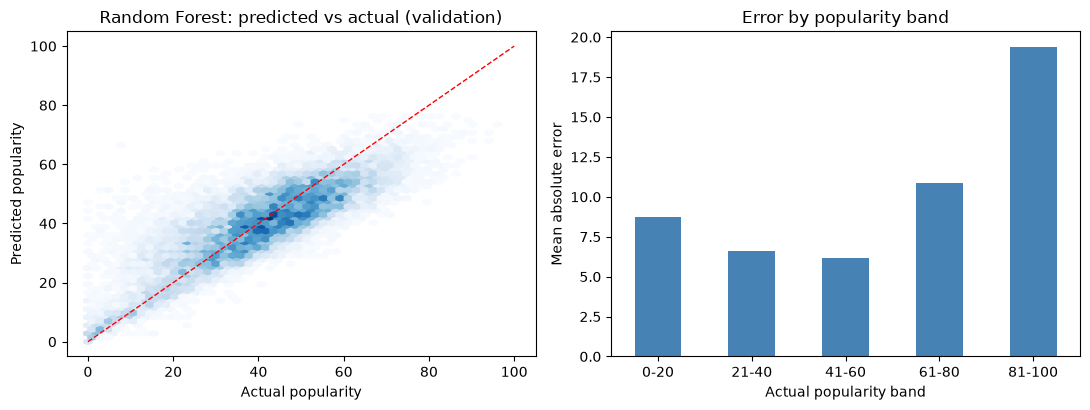

In [5]:
best_name = val_table.drop(index="Baseline (train mean)")["RMSE"].idxmin()
print("Best model on validation:", best_name)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hexbin(val[TARGET], val_preds[best_name], gridsize=50, cmap="Blues", mincnt=1)
ax[0].plot([0, 100], [0, 100], "r--", lw=1)
ax[0].set(xlabel="Actual popularity", ylabel="Predicted popularity", title=f"{best_name}: predicted vs actual (validation)")
err = val_preds[best_name] - val[TARGET]
bins = pd.cut(val[TARGET], [-1, 20, 40, 60, 80, 100], labels=["0-20", "21-40", "41-60", "61-80", "81-100"])
pd.Series(np.abs(err)).groupby(bins.values, observed=False).mean().plot.bar(ax=ax[1], color="steelblue", rot=0)
ax[1].set(xlabel="Actual popularity band", ylabel="Mean absolute error", title="Error by popularity band")
plt.tight_layout(); plt.savefig("results/fig_r3_reg_pred_vs_actual.png", dpi=150); plt.show()

## 4. Feature-group comparison
Does popularity depend more on how a song sounds or on who released it? Each model is re-trained with its tuned settings on four feature sets and scored on validation.

Note: the settings were tuned on the full feature set and reused here, so smaller feature sets may be slightly under-tuned.

In [6]:
from sklearn.base import clone
fg_rows = []
for gname, cols in groups.items():
    for name, gs in searches.items():
        m = clone(gs.best_estimator_)
        if "model__n_jobs" in m.get_params(): m.set_params(model__n_jobs=-1)
        m.fit(train[cols], train[TARGET])
        fg_rows.append({"features": gname, "n_cols": len(cols), "model": name,
                        **rc.regression_metrics(val[TARGET], m.predict(val[cols]))})
fg_table = pd.DataFrame(fg_rows)
fg_table.pivot(index="model", columns="features", values="RMSE")[["all", "no_artist", "metadata", "audio"]]

features,all,no_artist,metadata,audio
model,,,,
Decision Tree,10.240,14.655,10.253,15.023
Random Forest,9.395,13.834,9.297,14.667
Ridge,10.648,15.402,11.078,15.485
k-NN,11.865,14.981,10.170,15.374


features,all,no_artist,metadata,audio
model,,,,
Decision Tree,0.626,0.234,0.625,0.195
Random Forest,0.685,0.317,0.692,0.232
Ridge,0.595,0.154,0.562,0.144
k-NN,0.498,0.199,0.631,0.157


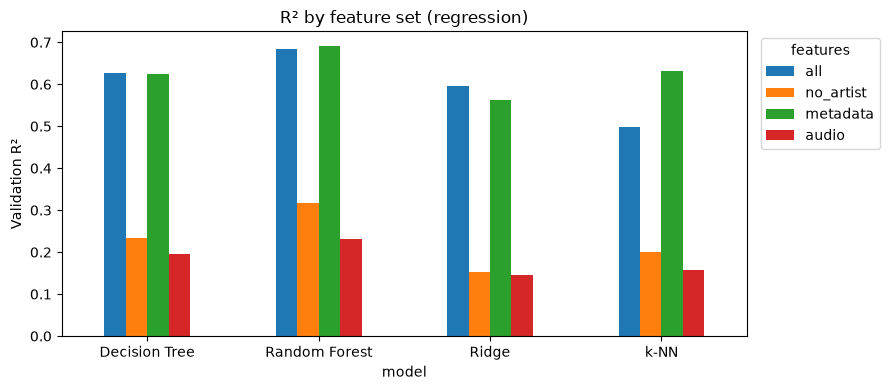

In [7]:
piv = fg_table.pivot(index="model", columns="features", values="R2")[["all", "no_artist", "metadata", "audio"]]
display(piv)
piv.plot.bar(figsize=(9, 4), rot=0)
plt.ylabel("Validation R²"); plt.title("R² by feature set (regression)"); plt.legend(title="features", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig("results/fig_r3_reg_feature_groups.png", dpi=150); plt.show()

## 5. Which features matter? (Random Forest, permutation importance)
Permutation importance = how much validation RMSE gets worse when one feature's values are shuffled. It is measured on validation data (5,000 tracks), so it is less biased than the tree's built-in importance. One-hot genre columns are scored separately.

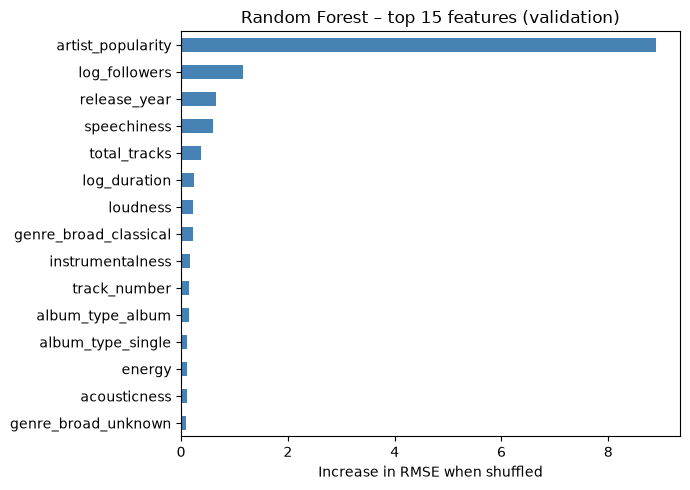

,RMSE increase
artist_popularity,8.898
log_followers,1.151
release_year,0.655
speechiness,0.591
total_tracks,0.370
log_duration,0.237
loudness,0.224
genre_broad_classical,0.219
instrumentalness,0.168
track_number,0.151


In [8]:
sample = val.sample(5000, random_state=rc.SEED)
pi = permutation_importance(models["Random Forest"], sample[FEATS], sample[TARGET],
                            scoring=SCORING, n_repeats=5, random_state=rc.SEED, n_jobs=1)  # n_jobs=1: parallel copies of the forest use too much RAM
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False)
imp.head(15).iloc[::-1].plot.barh(figsize=(7, 5), color="steelblue")
plt.xlabel("Increase in RMSE when shuffled"); plt.title("Random Forest – top 15 features (validation)")
plt.tight_layout(); plt.savefig("results/fig_r3_reg_importance.png", dpi=150); plt.show()
imp.head(15).to_frame("RMSE increase")

## 6. Save results

In [9]:
tuning_table.to_csv("results/r3_reg_tuning.csv")
val_table.to_csv("results/r3_reg_validation.csv")
fg_table.to_csv("results/r3_reg_feature_groups.csv", index=False)
imp.to_csv("results/r3_reg_rf_permutation_importance.csv", header=["rmse_increase"])
best_params = {n: {k.replace("model__", ""): v for k, v in gs.best_params_.items()} for n, gs in searches.items()}
json.dump(best_params, open("results/r3_reg_best_params.json", "w"), indent=2, default=str)
print(json.dumps(best_params, indent=2, default=str))

{
  "Ridge": {
    "alpha": 10
  },
  "Decision Tree": {
    "max_depth": 10,
    "min_samples_leaf": 10
  },
  "k-NN": {
    "n_neighbors": 15,
    "weights": "distance"
  },
  "Random Forest": {
    "max_features": 0.33,
    "min_samples_leaf": 1
  }
}


## 7. Final test (run once, at the very end)
Leave `RUN_TEST = False` until the MLP (R4) is tuned and the group has fixed its final models. Then set it to `True`, run this cell once, and report those numbers in the Results section.

In [10]:
RUN_TEST = False
if RUN_TEST:
    final = {"Baseline (train mean)": DummyRegressor(strategy="mean")}
    final.update({n: clone(gs.best_estimator_) for n, gs in searches.items()})
    test_table = rc.final_test(final, train, test, FEATS, TARGET, "regression")
    test_table.to_csv("results/r3_reg_TEST.csv", index=False)
    display(test_table)